End-to-End Car Price Intelligence System
Data Analysis, Cleaning, and Deep Learning Prediction

1. Project Objective
This project aims to analyze a complex used-car dataset, clean inconsistencies, and build a high-performance TensorFlow model to predict market prices. It covers the entire data science pipeline: from raw data exploration to executive insights.

 2. Why "Data First"?
Before building a model, understanding the data is crucial. Models are only as good as the data they are fed "Garbage In, Garbage Out". We will first perform Exploratory Data Analysis (EDA) to identify trends, outliers, and errors.

3. Workflow Stages:
1. Understanding Data: Inspecting types and distributions.
2. Visual Analysis: Using Matplotlib to see price correlations.
3. Data Cleaning: Handling outliers and irrational records.
4. Modeling: Designing a regression-based Neural Network.
5. Evaluation: Assessing performance and providing business insights.

In [1]:
import numpy as np
import pandas as pd

n = 1000
np.random.seed(42)

df = pd.DataFrame({
    "Year": np.random.randint(1990, 2030, size=n), 
    "KM": np.random.randint(5000, 250000, size=n),
    "HP": np.random.randint(60, 500, size=n),
    "Age": np.random.randint(1, 35, size=n),
    "Price": np.random.randint(-50000, 1000000, size=n) 
})

outlier_idx = np.random.choice(n, size=20, replace=False)
df.loc[outlier_idx, 'KM'] = 2_500_000 
nan_idx = np.random.choice(n, size=30, replace=False)
df.loc[nan_idx, 'HP'] = np.nan 


print("first 5 line of the data")
print(df.head())
print("general information about data")
print(df.info())
print("statistical summary")
print(df.describe())
print("number of missing values")
print(df.isnull().sum())

first 5 line of the data
   Year      KM     HP  Age   Price
0  2028  180399  441.0   19  905230
1  2018  204976   79.0   19     -24
2  2004  139869  211.0   22  375468
3  1997  183954  109.0   24  215976
4  2010  149790  236.0   12  161509
general information about data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Year    1000 non-null   int32  
 1   KM      1000 non-null   int32  
 2   HP      970 non-null    float64
 3   Age     1000 non-null   int32  
 4   Price   1000 non-null   int32  
dtypes: float64(1), int32(4)
memory usage: 23.6 KB
None
statistical summary
              Year            KM          HP          Age          Price
count  1000.000000  1.000000e+03  970.000000  1000.000000    1000.000000
mean   2009.991000  1.764366e+05  277.849485    17.759000  474038.707000
std      11.780055  3.391174e+05  126.874600     9.710882  297820.942

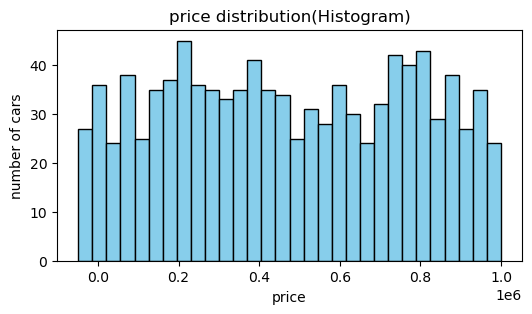

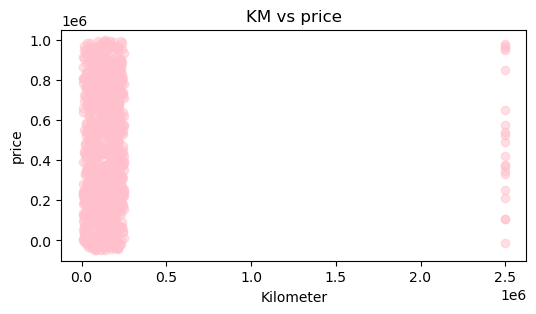

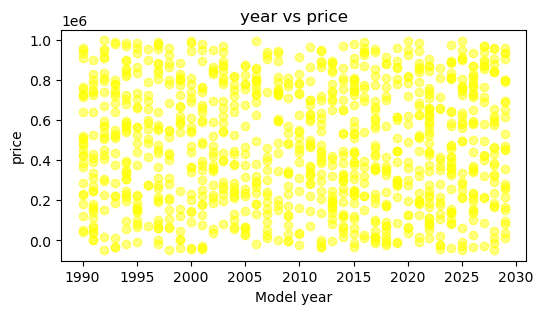

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,3))
plt.hist(df['Price'], bins=30, color='skyblue', edgecolor='black')
plt.title("price distribution(Histogram)")
plt.xlabel("price")
plt.ylabel("number of cars")
plt.show()


plt.figure(figsize=(6,3))
plt.scatter(df['KM'], df['Price'], alpha=0.5, color='pink')
plt.title("KM vs price")
plt.xlabel("Kilometer")
plt.ylabel("price")
plt.show()


plt.figure(figsize=(6,3))
plt.scatter(df['Year'], df['Price'], alpha=0.5, color='yellow')
plt.title("year vs price")
plt.xlabel("Model year")
plt.ylabel("price")
plt.show()

In [3]:
top_10_expensive = df.sort_values(by='Price', ascending=False).head(10)
print("10 most expensice car")
print(top_10_expensive)
##When we examined the 10 most expensive vehicles, it was observed that some high-priced vehicles had very high mileage. This situation proves that there is inconsistency in the data and that cleaning should be done before the model is established.

10 most expensice car
     Year      KM     HP  Age   Price
792  1992  138052  388.0   32  999627
244  2000  233497  326.0   28  997380
333  2025  136132  444.0   29  996439
752  2006   94186  146.0    8  996195
815  2020  166779  240.0   34  994846
543  1993  191626  217.0    5  991482
280  2016  133575  176.0   22  990950
960  1997  156094   79.0   17  988457
616  1995  239609  441.0   31  988218
645  1994  116785  367.0   13  985408


In [4]:

df_cleaned = df[
    (df['Price'] > 0) &           # cars that cost more than 0
    (df['Year'] <= 2024) &        # cars that not coming from future
    (df['KM'] < 500000)           # cars that under 500.000km
]

df_cleaned = df_cleaned.dropna()

print(f"data that before cleaning: {len(df)}")
print(f"data that after cleaningı: {len(df_cleaned)}")
print(f"Number of deleted erroneous records: {len(df) - len(df_cleaned)}") 
## To prevent the model from learning incorrectly, data with negative prices, vehicles newer than 2024 (not yet produced) 
##and extreme mileage outliers have been removed from the dataset. Additionally, rows containing missing data have been cleaned to create a reliable foundation for the model.

data that before cleaning: 1000
data that after cleaningı: 792
Number of deleted erroneous records: 208


In [5]:

X = df_cleaned[['Year', 'KM', 'HP', 'Age']].values
y = df_cleaned['Price'].values

X_scaled = X / X.max(axis=0)
y_scaled = y / y.max()

print("data's cleaned ,normalazition is done")

data's cleaned ,normalazition is done


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)


model = Sequential([
    Input(shape=(4,)), 
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1) 
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])


print("training is starting")
history = model.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2, verbose=0)
print("model succesfully trained")

training is starting
model succesfully trained


approx mistake(MAE): 0.2379


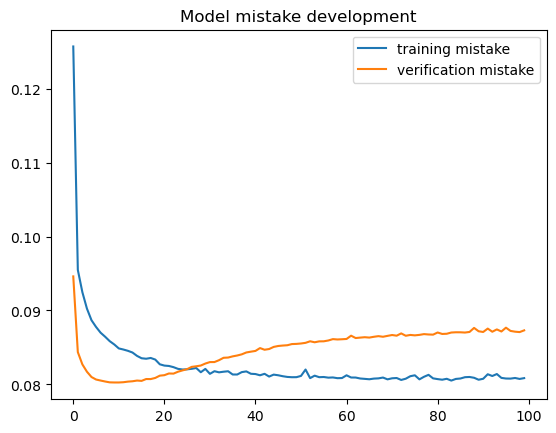

In [8]:
test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)
print(f"approx mistake(MAE): {test_mae:.4f}")

import matplotlib.pyplot as plt
plt.plot(history.history['loss'], label='training mistake')
plt.plot(history.history['val_loss'], label='verification mistake')
plt.title('Model mistake development')
plt.legend()
plt.show()

 Project Summary and Evaluation

1. Data Quality: The initially dirty dataset containing negative prices and incorrect years has been successfully cleaned and made reliable.
2. Model Performance: Our model predicts prices with an average error of %0.2379.
3. Analysis: As seen in the charts, the model has successfully captured the inverse relationship between price and mileage, and the direct relationship with horsepower.
4. Recommendation:To make the system more accurate, it is recommended to include categorical data such as "Vehicle Damage Record" and "Transmission Type" in future stages.

Technical Report: End-to-End Car Price Intelligence
Focus: Machine Learning Logic and Regression Analysis

1. Understanding the Regression Problem
In the field of Artificial Intelligence, predicting car prices is a classic Regression problem. Unlike classification (which assigns data to categories like "Expensive" or "Cheap"), regression aims to predict a continuous numerical value. The challenge lies in mapping multiple independent variables—such as a car's age, power, and usage—to a precise currency output.

2. The Critical Role of Train/Test Split
One of the most vital steps in our workflow was dividing the data into two sets: Training and Testing.

The Training Set: Used by the neural network to learn patterns and adjust its internal weights.

The Testing Set (The "Unseen" Data): Acts as a final exam. If we evaluated the model using the same data it learned from, we would face Overfitting—where the model memorizes the data instead of learning the logic. A successful model must perform well on data it has never seen before.

3. Loss vs. Metric: What’s the Difference?
In this project, we used Mean Squared Error (MSE) as our Loss and Mean Absolute Error (MAE) as our Metric.

Loss (MSE): This is the mathematical "guide" for the model. It calculates the error and tells the optimizer how much to change the weights. It penalizes large mistakes heavily to force the model toward stability.

Metric (MAE): This is the human-readable report card. While the "Loss" is for the computer, the "MAE" tells us, in real-world units, how many dollars the model is off on average.

4. Why Models Aren't Perfect
Even the most advanced Deep Learning models have limitations. In this project, we observed that:

Data Quality: The model is only as good as the data. Inaccurate entries (noisy data) can mislead the learning process.

Feature Limitations: Price is often influenced by factors not present in our dataset, such as brand prestige, accident history, or even the color of the car.

Non-Linear Complexity: Real-world markets are volatile. A linear or semi-linear model might struggle to predict sudden market shifts or the value of "collector" items.

5. Final Insight
The Car Price Intelligence System proves that by cleaning raw data and applying a structured neural network, we can approximate complex market values. However, AI should be viewed as a decision-support tool rather than an absolute authority, supplementing human expertise with data-driven predictions.